# 3.2 — Les optimisateurs : de SGD à Adam, ce qui change vraiment

**Navigation** : [<< 3.1-Retropropagation](3.1-Retropropagation.ipynb) | [Index](README.md) | [3.3 — Régularisation >>](3.3-Regularisation.ipynb)

**Kernel** : Python 3 (NumPy pur + comparaison PyTorch) · **CPU** : oui · **Durée** : 2–3 heures (étude et exercices)

***

## Introduction

[3.1](3.1-Retropropagation.ipynb) a entraîné un réseau avec la descente de gradient. Les variantes comme momentum et Adam ajoutent des états et modifient la règle de mise à jour ; ce carnet ouvre les boîtes centrales et les confronte à un moteur réel :

| optimiseur | année | idée en une ligne |
|---|---|---|
| SGD + momentum | 1964 / 1986 | une boule qui accumule de l'élan dans le ravin |
| Adagrad | 2011 | un learning rate **par paramètre**, qui décroît avec l'historique |
| RMSProp | 2012 | la moyenne glissante qui répare l'accumulation infinie d'Adagrad |
| Adam | 2014 | RMSProp **+** momentum, avec la correction de biais des premiers pas |

La discipline est celle de 3.1 : **from scratch PUIS framework**. Chaque optimiseur est écrit
en NumPy pur (l'état — momentum, accumulateurs — est explicite), puis **validé contre
`torch.optim`** : les paramètres sont comparés sur plusieurs pas avec une tolérance explicite. Ensuite seulement, le grand comparatif — trajectoires superposées sur la surface
de Beale, courbes de perte du MLP de 3.1 sur 3 graines — et les **schedules** de learning rate
qui terminent le tableau.

**Objectifs** : comparer les états et les trajectoires, puis étudier les schedules. **Prérequis** : gradients, tableaux et rétropropagation. **Durée** : 2–3 heures. [Version C#](3.2-Optimisateurs-CSharp.ipynb).


***

## 1. Le problème visible : le même paysage, trois destins

Le terrain des trajectoires : la fonction de **Beale**, courbée en vallon étroit, minimum global
en $(3, 0{,}5)$. Le rappel de [2.2](../02-ML-Cours/2.2-Descente-de-gradient.ipynb) y prend sa
forme profonde : le learning rate influe sur la trajectoire et la convergence selon le paysage et le budget.

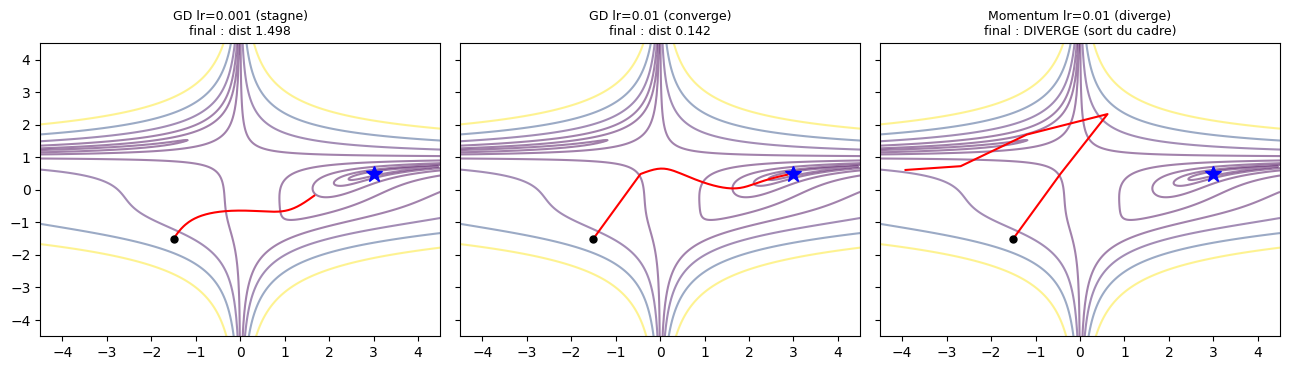

In [1]:
# Terrain : Beale + gradient analytique, et les trois regimes du lr
import numpy as np
import matplotlib.pyplot as plt

def beale(x, y):
    return (1.5 - x + x * y) ** 2 + (2.25 - x + x * y ** 2) ** 2 + (2.625 - x + x * y ** 3) ** 2

def beale_grad(x, y):
    dx = 2 * (1.5 - x + x * y) * (y - 1) + 2 * (2.25 - x + x * y ** 2) * (y ** 2 - 1) \
         + 2 * (2.625 - x + x * y ** 3) * (y ** 3 - 1)
    dy = 2 * (1.5 - x + x * y) * x + 2 * (2.25 - x + x * y ** 2) * (2 * x * y) \
         + 2 * (2.625 - x + x * y ** 3) * (3 * x * y ** 2)
    return np.array([dx, dy])

START = np.array([-1.5, -1.5])
OPT_MIN = np.array([3.0, 0.5])

def gd_trajectory(lr, nsteps=400, momentum=0.0):
    w = START.astype(float).copy()
    buf = np.zeros(2)
    traj = [w.copy()]
    with np.errstate(over="ignore", invalid="ignore"):
        for _ in range(nsteps):
            g = beale_grad(*w)
            buf = momentum * buf + g
            w = w - lr * buf
            if not np.isfinite(w).all():
                break
            traj.append(w.copy())
    return np.array(traj)

cases = [("GD lr=0.001 (stagne)", 0.001, 0.0), ("GD lr=0.01 (converge)", 0.01, 0.0),
         ("Momentum lr=0.01 (diverge)", 0.01, 0.9)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
gx = np.linspace(-4.5, 4.5, 400); gy = np.linspace(-4.5, 4.5, 400)
GX, GY = np.meshgrid(gx, gy); GZ = beale(GX, GY)
for ax, (label, lr, mom) in zip(axes, cases):
    tr = gd_trajectory(lr, momentum=mom)
    # la norme d'un point gigantesque deborde avant le test : meme garde que la trajectoire
    with np.errstate(over="ignore", invalid="ignore"):
        diverged = not np.isfinite(tr[-1]).all() or np.linalg.norm(tr[-1]) > 1e4
    tr_win = tr[np.all(np.abs(tr) <= 4.5, axis=1)]  # la trajectoire sort du cadre : on l'y coupe
    ax.contour(GX, GY, GZ, levels=np.logspace(-1, 3, 8), cmap="viridis", alpha=0.5)
    ax.plot(tr_win[:, 0], tr_win[:, 1], "r-", lw=1.5)
    ax.plot(*START, "ko", ms=5); ax.plot(*OPT_MIN, "b*", ms=12)
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5)
    fin = "DIVERGE (sort du cadre)" if diverged else f"dist {np.linalg.norm(tr[-1] - OPT_MIN):.3f}"
    ax.set_title(f"{label}\nfinal : {fin}", fontsize=9)
plt.tight_layout(); plt.show()

**Lecture.** Trois destins sur le même paysage : lr trop petit, la bille rampe et n'atteint
pas le vallon en 400 pas ; lr juste, elle descend ; momentum + lr un peu trop grand, elle
s'emballe carrément — l'élan accumulé amplifie le dépassement au lieu de l'amortir, au point
de **sortir du cadre** (troisième panneau : la trajectoire explose hors de la fenêtre). Le
problème que les quatre optimisateurs de ce notebook attaquent est exactement là : **rendre le
pas sûr sans le rendre minuscule**.

***

## 2. Momentum : la boule dans le ravin

L'idée de Polyak (1964), devenue la norme avec Rumelhart : la mise à jour **accumule** le
gradient au lieu de le consommer brut — $v \leftarrow \mu v + \nabla L$, puis
$\theta \leftarrow \theta - \eta v$ avec $\mu = 0{,}9$. Dans un vallon étroit, les
composantes qui pointent à travers le ravin s'annulent de pas en pas (elles alternent de
signe), les composantes le long du ravin s'additionnent : la bille oscille moins et avance plus
vite. C'est la lecture d'usage du phénomène visible en section 1 : le momentum amplifie le
mouvement cohérent, pas le bruit.

In [2]:
# GD pur et momentum en NumPy pur, valides contre torch.optim.SGD
def gd_step(params, grads, state, lr=0.05):
    for i, (p, g) in enumerate(zip(params, grads)):
        params[i] = p - lr * g

def make_optim_state(params):
    return [np.zeros_like(p) for p in params]

def sgd_momentum_step(params, grads, state, lr=0.05, momentum=0.9):
    for i, (p, g) in enumerate(zip(params, grads)):
        state[i] = momentum * state[i] + g
        params[i] = p - lr * state[i]

def validate_torch(name, np_step, torch_opt_fn, seed=42):
    rng = np.random.RandomState(seed)
    shapes = [(2, 32), (32,), (32, 2), (2,)]
    ref = [rng.randn(*s) for s in shapes]
    params_np = [q.copy() for q in ref]
    grads_np = [rng.randn(*s) for s in shapes]
    state = make_optim_state(params_np)
    np_step(params_np, grads_np, state)
    tp = [torch.tensor(q, dtype=torch.float64) for q in ref]
    for q in tp: q.requires_grad_(True)
    for q, g in zip(tp, grads_np): q.grad = torch.tensor(g, dtype=torch.float64)
    torch_opt_fn(tp).step()
    return max(np.abs(a - b.detach().numpy()).max() for a, b in zip(params_np, tp))

import torch

def sgd_torch(tp):
    return torch.optim.SGD(tp, lr=0.05, momentum=0.9)

ec_gd = validate_torch("GD", gd_step, lambda tp: torch.optim.SGD(tp, lr=0.05))
ec = validate_torch("SGD+momentum", sgd_momentum_step, sgd_torch)
print(f"GD pur       : ecart max apres 1 pas NumPy vs torch = {ec_gd:.2e}")
print(f"SGD+momentum : ecart max apres 1 pas NumPy vs torch = {ec:.2e}")

GD pur       : ecart max apres 1 pas NumPy vs torch = 1.11e-16
SGD+momentum : ecart max apres 1 pas NumPy vs torch = 1.11e-16


**Lecture.** Les validations passent : GD pur à **1,11e-16** (même formule, une soustraction),
momentum à **1,11e-16** près (float64). Le détail qui compte : torch écrit
`buf = momentum * buf + grad` (dampening par défaut à 0) — exactement notre forme.

***

## 3. Adagrad : un learning rate par paramètre

Duchi et al. (2011) renversent la question : au lieu d'un $\eta$ global, chaque paramètre
reçoit un pas divisé par la **racine de la somme des carrés** de ses gradients passés :

$$G \leftarrow G + g \odot g, \quad \theta \leftarrow \theta - \eta \, \frac{g}{\sqrt{G} + \varepsilon}$$

Un paramètre souvent remué (grand gradient fréquent) voit son pas rétrécir ; un paramètre
calme garde un pas presque entier. Sur Beale, cela se voit immédiatement : Adagrad démarre
vite puis **ralentit structurellement** — $G$ ne fait que croître, le dénominateur ne décroît pas, même si le pas effectif dépend aussi du gradient courant.
C'est le défaut célèbre : l'accumulation infinie.

In [3]:
# Adagrad en NumPy pur, valide contre torch.optim.Adagrad
def adagrad_step(params, grads, state, lr=1.0, eps=1e-10):
    for i, (p, g) in enumerate(zip(params, grads)):
        state[i] = state[i] + g ** 2
        params[i] = p - lr * g / (np.sqrt(state[i]) + eps)

def adagrad_torch(tp):
    return torch.optim.Adagrad(tp, lr=1.0, eps=1e-10)

ec = validate_torch("Adagrad", adagrad_step, adagrad_torch)
print(f"Adagrad : ecart max apres 1 pas NumPy vs torch = {ec:.2e}")
print("(torch : initial_accumulator_value=0, lr_decay=0 — les memes valeurs par defaut que nous)")

Adagrad : ecart max apres 1 pas NumPy vs torch = 0.00e+00
(torch : initial_accumulator_value=0, lr_decay=0 — les memes valeurs par defaut que nous)


**Lecture.** Adagrad validé à **0,00e+00** — identique au bit près. Noter le $\eta = 1{,}0$ : chez Adagrad, le learning
rate de référence est grand parce que la normalisation par $\sqrt{G}$ le divise mécaniquement
— c'est déjà un pas adaptatif, pas un pas global.

***

## 4. RMSProp puis Adam : réparer l'accumulation, ajouter l'élan

**RMSProp** (Hinton, cours 6e, 2012 — jamais publié en article) remplace la somme infinie par
une **moyenne glissante** : $v \leftarrow \alpha v + (1-\alpha) g^2$ avec $\alpha = 0{,}99$.
La moyenne glissante peut adapter le pas aux gradients récents ; elle ne garantit pas un pas stationnaire.

**Adam** (Kingma & Ba, 2014) ajoute la seconde moitié : un momentum $m$ sur le gradient
**et** la normalisation $v$, plus la **correction de biais des premiers pas** — à l'initialisation
$m$ et $v$ partent de zéro, donc $m/(1-\beta_1^t)$ et $v/(1-\beta_2^t)$ ré-échelonnent les
premières itérations pour corriger les estimateurs initialisés à zéro : selon les gradients, le pas non corrigé peut être plus grand ou plus petit :

$$m \leftarrow \beta_1 m + (1-\beta_1) g, \quad v \leftarrow \beta_2 v + (1-\beta_2) g^2$$
$$\theta \leftarrow \theta - \eta \, \frac{m / (1-\beta_1^t)}{\sqrt{v / (1-\beta_2^t)} + \varepsilon}$$

avec $(\beta_1, \beta_2, \varepsilon) = (0{,}9, 0{,}999, 10^{-8})$ — les défauts de torch.

In [4]:
# RMSProp puis Adam en NumPy pur, chacun valide contre torch
def rmsprop_step(params, grads, state, lr=0.05, alpha=0.99, eps=1e-8):
    for i, (p, g) in enumerate(zip(params, grads)):
        state[i] = alpha * state[i] + (1 - alpha) * g ** 2
        params[i] = p - lr * g / (np.sqrt(state[i]) + eps)

def adam_step(params, grads, state, lr=0.05, b1=0.9, b2=0.999, eps=1e-8, t=1):
    # state contient [m..., v...] concatenes : geree par l'appelant via make_adam_state
    for i, (p, g) in enumerate(zip(params, grads)):
        m, v = state[0][i], state[1][i]
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g ** 2
        state[0][i], state[1][i] = m, v
        params[i] = p - lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)

def make_adam_state(params):
    return [make_optim_state(params), make_optim_state(params)]

# Adaptateurs pour validate_torch (un seul etat plat) :
def rmsprop_validate(params, grads, flat_state, lr=0.05):
    rmsprop_step(params, grads, flat_state, lr=lr)

def adam_validate(params, grads, _flat, lr=0.05):
    adam_step(params, grads, [make_optim_state(params), make_optim_state(params)], lr=lr, t=1)

ec_rms = validate_torch("RMSProp", rmsprop_validate,
                        lambda tp: torch.optim.RMSprop(tp, lr=0.05, alpha=0.99, eps=1e-8))
ec_adam = validate_torch("Adam", adam_validate,
                         lambda tp: torch.optim.Adam(tp, lr=0.05, betas=(0.9, 0.999), eps=1e-8))
print(f"RMSProp : ecart max apres 1 pas NumPy vs torch = {ec_rms:.2e}")
print(f"Adam    : ecart max apres 1 pas NumPy vs torch = {ec_adam:.2e}")
print("(les 5 mises a jour du notebook - GD, momentum, Adagrad, RMSProp, Adam -")
print(" sont maintenant toutes validees contre leurs equivalents torch)")
# Trois gradients différents, mêmes états et mêmes quatre tenseurs que torch.optim.
def compare_multisteps(name, step, factory):
    rng=np.random.RandomState(42);shapes=[(2,32),(32,),(32,2),(2,)];p=[rng.randn(*shape) for shape in shapes]
    q=[torch.tensor(a.copy(),dtype=torch.float64,requires_grad=True) for a in p];opt=factory(q)
    state=make_adam_state(p) if name=="Adam" else make_optim_state(p)
    maxerr=0.0
    for t in range(1,4):
        g=[rng.randn(*shape) for shape in shapes]
        if name=="Adam": step(p,g,state,t=t)
        else: step(p,g,state)
        for z,grad in zip(q,g): z.grad=torch.tensor(grad,dtype=torch.float64)
        opt.step();opt.zero_grad()
        maxerr=max(maxerr,max(float(np.max(np.abs(a-b.detach().numpy()))) for a,b in zip(p,q)))
    return maxerr
for _name,_step,_factory in [("GD",gd_step,lambda q:torch.optim.SGD(q,lr=.05)),("Momentum",sgd_momentum_step,sgd_torch),("Adagrad",adagrad_step,lambda q:torch.optim.Adagrad(q,lr=1.0,eps=1e-10)),("RMSProp",rmsprop_step,lambda q:torch.optim.RMSprop(q,lr=.05,alpha=.99,eps=1e-8)),("Adam",adam_step,lambda q:torch.optim.Adam(q,lr=.05))]:
    _err=compare_multisteps(_name,_step,_factory);print(f"{_name} : 3 pas, écart max {_err:.3e}");assert _err<1e-12


RMSProp : ecart max apres 1 pas NumPy vs torch = 2.22e-16
Adam    : ecart max apres 1 pas NumPy vs torch = 1.11e-16
(les 5 mises a jour du notebook - GD, momentum, Adagrad, RMSProp, Adam -
 sont maintenant toutes validees contre leurs equivalents torch)
GD : 3 pas, écart max 2.220e-16
Momentum : 3 pas, écart max 2.220e-16
Adagrad : 3 pas, écart max 4.441e-16
RMSProp : 3 pas, écart max 4.441e-16
Adam : 3 pas, écart max 2.220e-16


**Lecture.** RMSProp à **2,22e-16**, Adam à **1,11e-16** : les cinq règles de mise à jour de l'histoire
sont écrites et **chacune est la sœur jumelle de sa version torch**, pas au pas d'epsilon — les paramètres sont comparés sur plusieurs pas à ceux de `torch.optim` avec les mêmes hyperparamètres. Ce qui reste à mesurer : ce que ces différences
*d'update* font sur de vraies trajectoires.

***

## 5. Le comparatif 2D : cinq trajectoires sur Beale

Même départ (-1,5 ; -1,5), 400 pas, même fonction — mais le learning rate de référence **par
famille** : c'est la mesure honnête (à lr égal, aucun régime ne se compare : GD exige petit,
Adagrad exige grand). Ce que la superposition doit révéler : la **personnalité du chemin**, pas
seulement le point d'arrivée.

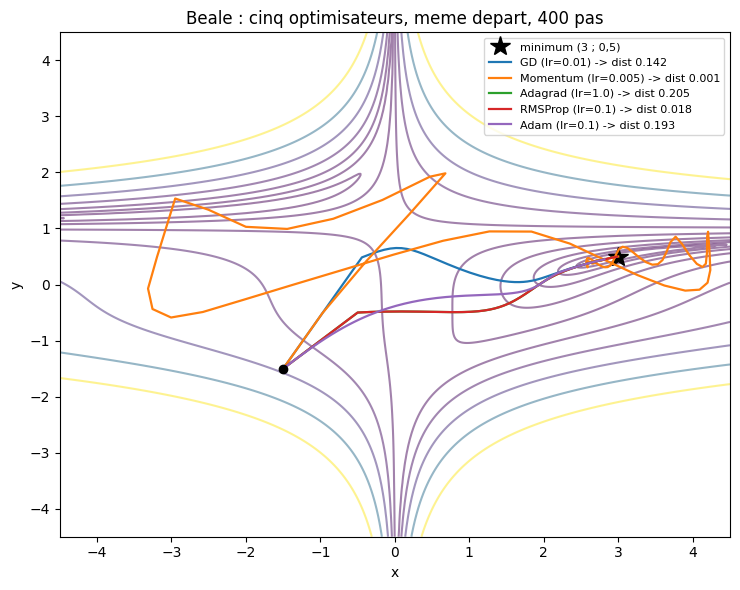

GD        lr= 0.01 -> dist finale au minimum 0.1424
Momentum  lr=0.005 -> dist finale au minimum 0.0006
Adagrad   lr=  1.0 -> dist finale au minimum 0.2054
RMSProp   lr=  0.1 -> dist finale au minimum 0.0176
Adam      lr=  0.1 -> dist finale au minimum 0.1935


In [5]:
# Trajectoires superposees : 5 optimisateurs, lr par famille, 400 pas
def run_optimizer(name, lr, nsteps=400):
    w = START.astype(float).copy()
    m = v = acc = buf = np.zeros(2)
    traj = [w.copy()]
    for t in range(1, nsteps + 1):
        g = beale_grad(*w)
        if name == "GD":
            w = w - lr * g
        elif name == "Momentum":
            buf = 0.9 * buf + g
            w = w - lr * buf
        elif name == "Adagrad":
            acc = acc + g ** 2
            w = w - lr * g / (np.sqrt(acc) + 1e-10)
        elif name == "RMSProp":
            v = 0.99 * v + 0.01 * g ** 2
            w = w - lr * g / (np.sqrt(v) + 1e-8)
        else:  # Adam
            m = 0.9 * m + 0.1 * g
            v = 0.999 * v + 0.001 * g ** 2
            w = w - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        traj.append(w.copy())
    return np.array(traj)

CONFS = [("GD", 0.01), ("Momentum", 0.005), ("Adagrad", 1.0), ("RMSProp", 0.1), ("Adam", 0.1)]
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.contour(GX, GY, GZ, levels=np.logspace(-1, 3, 10), cmap="viridis", alpha=0.5)
ax.plot(*OPT_MIN, "k*", ms=15, label="minimum (3 ; 0,5)")
for name, lr in CONFS:
    tr = run_optimizer(name, lr)
    ax.plot(tr[:, 0], tr[:, 1], lw=1.6,
            label=f"{name} (lr={lr}) -> dist {np.linalg.norm(tr[-1] - OPT_MIN):.3f}")
ax.plot(*START, "ko", ms=6)
ax.set_title("Beale : cinq optimisateurs, meme depart, 400 pas")
ax.legend(fontsize=8); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

for name, lr in CONFS:
    tr = run_optimizer(name, lr)
    print(f"{name:9s} lr={lr:5} -> dist finale au minimum {np.linalg.norm(tr[-1] - OPT_MIN):.4f}")

**Lecture.** Les distances au minimum et les cinq trajectoires figurent ci-dessus pour les taux choisis. Elles illustrent ces réglages et ce budget, sans établir un classement général ; l’effet de la correction de biais ne se déduit pas de ce seul comparatif.


***

## 6. Le comparatif MLP : le réseau de 3.1, cinq optimisateurs, trois graines

Le vallon 2D est une métaphore ; le test est le MLP 2-32-2 de [3.1](3.1-Retropropagation.ipynb)
sur `make_moons` (redéfini ci-dessous en compact). Cinq optimisateurs × **trois graines**
{0, 1, 2} (chaque graine = même init de poids pour les cinq), 1500 itérations full-batch,
courbes de perte superposées. Personne n'est favorisé : les lr viennent de la même discipline
de réglage grossier (les plages usuelles par famille).

Logits extrêmes : 0, 2000, ln(2) sous décalage commun et 0 pour classe maximale ±1e308


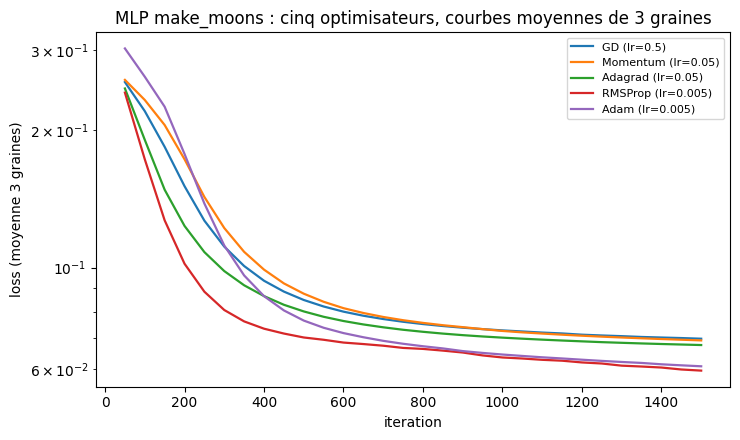

optimiseur loss finale (3 graines)    mediane
GD         ['0.0697', '0.0698', '0.0701'] 0.0698
Momentum   ['0.0684', '0.0695', '0.0699'] 0.0695
Adagrad    ['0.0655', '0.0671', '0.0704'] 0.0671
RMSProp    ['0.0585', '0.0591', '0.0609'] 0.0591
Adam       ['0.0585', '0.0614', '0.0625'] 0.0614
perte moyenne 3 graines @ iter  100 : GD 0.220  Momentum 0.233  Adagrad 0.190  RMSProp 0.173  Adam 0.262
perte moyenne 3 graines @ iter  300 : GD 0.111  Momentum 0.122  Adagrad 0.098  RMSProp 0.081  Adam 0.112
perte moyenne 3 graines @ iter  500 : GD 0.085  Momentum 0.088  Adagrad 0.080  RMSProp 0.070  Adam 0.077


In [6]:
# MLP du 3.1 en compact + boucles 5 optimisateurs x 3 graines
from sklearn.datasets import make_moons

SEED = 42
X_m, y_m = make_moons(n_samples=450, noise=0.20, random_state=SEED)
Y_m = np.eye(2)[y_m]
D, H, C = 2, 32, 2

def mlp_init(seed):
    rng = np.random.RandomState(seed)
    return [rng.randn(D, H) * np.sqrt(2.0 / D), np.zeros(H),
            rng.randn(H, C) * np.sqrt(2.0 / H), np.zeros(C)]

def mlp_loss_grads(params, X, Y):
    Z1 = X @ params[0] + params[1]; A1 = np.maximum(Z1, 0); Z2 = A1 @ params[2] + params[3]
    Zs = Z2 - Z2.max(axis=1, keepdims=True); E = np.exp(Zs); P = E / E.sum(axis=1, keepdims=True)
    loss = np.mean(np.log(np.exp(Zs).sum(axis=1)) - Zs[np.arange(len(Y)), Y.argmax(axis=1)])
    n = X.shape[0]
    dZ2 = (P - Y) / n
    dW2 = A1.T @ dZ2; db2 = dZ2.sum(axis=0)
    dA1 = dZ2 @ params[2].T; dZ1 = dA1 * (Z1 > 0)
    return loss, [X.T @ dZ1, dZ1.sum(axis=0), dW2, db2]

# Contrôles numériques indépendants sur deux classes extrêmes.
_extreme = [np.zeros((2,32)), np.zeros(32), np.zeros((32,2)), np.array([1000.,-1000.])]
assert np.isclose(mlp_loss_grads(_extreme, np.zeros((1,2)), np.array([[1.,0.]]))[0],0.)
assert np.isclose(mlp_loss_grads(_extreme, np.zeros((1,2)), np.array([[0.,1.]]))[0],2000.)
_extreme[3]=np.array([1e20,1e20]);_shifted=mlp_loss_grads(_extreme,np.zeros((1,2)),np.array([[1.,0.]]))[0]
assert np.isclose(_shifted,np.log(2),atol=1e-15)
assert np.isclose(_shifted,torch.nn.functional.cross_entropy(torch.tensor([[1e20,1e20]],dtype=torch.float64),torch.tensor([0])).item(),atol=1e-15)
_extreme[3]=np.array([1e308,-1e308])
with np.errstate(over="ignore"):
    assert mlp_loss_grads(_extreme,np.zeros((1,2)),np.array([[1.,0.]]))[0]==0.
print("Logits extrêmes : 0, 2000, ln(2) sous décalage commun et 0 pour classe maximale ±1e308")

OPT_LRS = {"GD": 0.5, "Momentum": 0.05, "Adagrad": 0.05, "RMSProp": 0.005, "Adam": 0.005}
SEEDS_MLP = (0, 1, 2)
ITERS = 1500

def train_mlp(name, seed, lr=None, schedule=None):
    lr = lr or OPT_LRS[name]
    p = mlp_init(seed)
    m = [np.zeros_like(q) for q in p]; v = [np.zeros_like(q) for q in p]
    acc = [np.zeros_like(q) for q in p]; buf = [np.zeros_like(q) for q in p]
    hist = []
    for t in range(1, ITERS + 1):
        lr_t = schedule(t, lr) if schedule else lr
        _, g = mlp_loss_grads(p, X_m, Y_m)
        for i in range(len(p)):
            if name == "GD":
                p[i] = p[i] - lr_t * g[i]
            elif name == "Momentum":
                buf[i] = 0.9 * buf[i] + g[i]
                p[i] = p[i] - lr_t * buf[i]
            elif name == "Adagrad":
                acc[i] = acc[i] + g[i] ** 2
                p[i] = p[i] - lr_t * g[i] / (np.sqrt(acc[i]) + 1e-10)
            elif name == "RMSProp":
                v[i] = 0.99 * v[i] + 0.01 * g[i] ** 2
                p[i] = p[i] - lr_t * g[i] / (np.sqrt(v[i]) + 1e-8)
            else:  # Adam
                m[i] = 0.9 * m[i] + 0.1 * g[i]
                v[i] = 0.999 * v[i] + 0.001 * g[i] ** 2
                p[i] = p[i] - lr_t * (m[i] / (1 - 0.9 ** t)) / (np.sqrt(v[i] / (1 - 0.999 ** t)) + 1e-8)
        if t % 50 == 0:
            loss, _ = mlp_loss_grads(p, X_m, Y_m)
            hist.append((t, loss))
    return hist

results = {name: [train_mlp(name, s) for s in SEEDS_MLP] for name in OPT_LRS}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, runs in results.items():
    ts = [t for t, _ in runs[0]]
    mean_curve = np.mean([[l for _, l in r] for r in runs], axis=0)
    ax.plot(ts, mean_curve, lw=1.6, label=f"{name} (lr={OPT_LRS[name]})")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("loss (moyenne 3 graines)")
ax.set_title("MLP make_moons : cinq optimisateurs, courbes moyennes de 3 graines")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'optimiseur':10s} {'loss finale (3 graines)':26s} mediane")
for name, runs in results.items():
    finals = sorted(r[-1][1] for r in runs)
    med = finals[1]
    print(f"{name:10s} {[f'{f:.4f}' for f in finals]!s:26s} {med:.4f}")

for t_check in (100, 300, 500):
    line = "  ".join(f"{name} {np.mean([dict(r)[t_check] for r in runs]):.3f}"
                     for name, runs in results.items())
    print(f"perte moyenne 3 graines @ iter {t_check:4d} : {line}")

**Lecture.** Les pertes finales par graine, leurs médianes et les moyennes aux itérations 100, 300 et 500 sont affichées ci-dessus. Ces résultats dépendent de l’initialisation et des taux choisis ; ils ne prouvent ni supériorité générale ni causalité de la correction de biais.


## Exercice 1 : Nesterov, convention PyTorch

Implémentez `buf = momentum*buf + grad` puis `p -= lr*(grad + momentum*buf)` : c’est la convention de `torch.optim.SGD(nesterov=True)` aux mêmes coordonnées. Une interprétation lookahead classique peut utiliser un autre système de coordonnées. Comparez trois gradients variables puis une trajectoire Beale de 400 pas avec gradient recalculé.


In [7]:
# Exercice 1 : convention SGD Nesterov de PyTorch, pas de gradient lookahead.
def nesterov_step(params, grads, state, lr=.05, momentum=.9):
    return NotImplemented  # TODO : modifier params et state en place

p=[np.array([1.,-2.])]; state=make_optim_state(p)
if nesterov_step(p,[np.array([2.,-3.])],state) is NotImplemented:
    print("Exercice 1 à compléter")
else:
    try:
        p=[np.array([1.,-2.])];state=make_optim_state(p);q=torch.tensor([1.,-2.],dtype=torch.float64,requires_grad=True)
        opt=torch.optim.SGD([q],lr=.05,momentum=.9,nesterov=True)
        ok=True
        for g in (np.array([2.,-3.]),np.array([-.5,1.25]),np.array([3.,.2])):
            nesterov_step(p,[g],state);q.grad=torch.tensor(g,dtype=torch.float64);opt.step();opt.zero_grad()
            ok &= np.allclose(p[0],q.detach().numpy(),rtol=1e-12,atol=1e-12)
        # Réévaluer le vrai gradient de Beale à chaque position sur 400 pas.
        p=[START.copy()];state=make_optim_state(p);q=torch.tensor(START.copy(),dtype=torch.float64,requires_grad=True)
        opt=torch.optim.SGD([q],lr=.005,momentum=.9,nesterov=True)
        for _ in range(400):
            g=beale_grad(*p[0]);nesterov_step(p,[g],state,lr=.005)
            q.grad=torch.tensor(beale_grad(*q.detach().numpy()),dtype=torch.float64);opt.step();opt.zero_grad()
        ok &= np.allclose(p[0],q.detach().numpy(),rtol=1e-9,atol=1e-9)
        print("Fixtures Nesterov validées" if ok else "Réponse incorrecte")
    except (TypeError,ValueError,IndexError): print("Réponse incorrecte")


Exercice 1 à compléter


***

## 7. Les schedules : le learning rate qui descend avec le temps

Dernier étage, avec une question d'honnêteté : **le schedule paie-t-il toujours ?** Deux
schedules canoniques : **step** ($\eta$ divisé par 2 toutes les 500 itérations) et
**cosinus** (décroissance douce de $\eta$ à $\eta/50$). Deux régimes testés, Adam constant
en témoin dans les deux : (a) notre MLP **full-batch déterministe** ; (b) le même en
**mini-batch 32** — le gradient devient bruité, et c'est le régime pour lequel les schedules
ont été inventés.

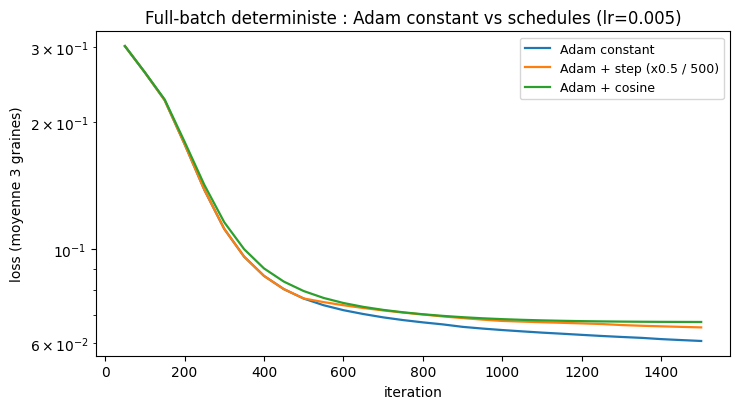

Adam constant              loss finale mediane (3 graines) : 0.0614
Adam + step (x0.5 / 500)   loss finale mediane (3 graines) : 0.0666
Adam + cosine              loss finale mediane (3 graines) : 0.0683


In [8]:
# Regime (a) : full-batch deterministe, Adam constant vs schedules, 3 graines
def sched_step(t, lr, step_every=500, gamma=0.5):
    return lr * gamma ** (t // step_every)

def sched_cosine(t, lr, t_max=ITERS):
    eta_min = lr / 50
    return eta_min + 0.5 * (lr - eta_min) * (1 + np.cos(np.pi * t / t_max))

sched_runs = {
    "Adam constant": [train_mlp("Adam", s) for s in SEEDS_MLP],
    "Adam + step (x0.5 / 500)": [train_mlp("Adam", s, schedule=sched_step) for s in SEEDS_MLP],
    "Adam + cosine": [train_mlp("Adam", s, schedule=sched_cosine) for s in SEEDS_MLP],
}
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, runs in sched_runs.items():
    ts = [t for t, _ in runs[0]]
    mean_curve = np.mean([[l for _, l in r] for r in runs], axis=0)
    ax.plot(ts, mean_curve, lw=1.6, label=name)
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("loss (moyenne 3 graines)")
ax.set_title("Full-batch deterministe : Adam constant vs schedules (lr=0.005)")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

for name, runs in sched_runs.items():
    finals = sorted(r[-1][1] for r in runs)
    print(f"{name:26s} loss finale mediane (3 graines) : {finals[1]:.4f}")

**Lecture (full-batch).** Les médianes des trois graines et les courbes sont affichées ci-dessus. Elles comparent ces schedules pour 1500 pas sur ce jeu ; la réduction de taux n’assure pas une amélioration sur tout problème.


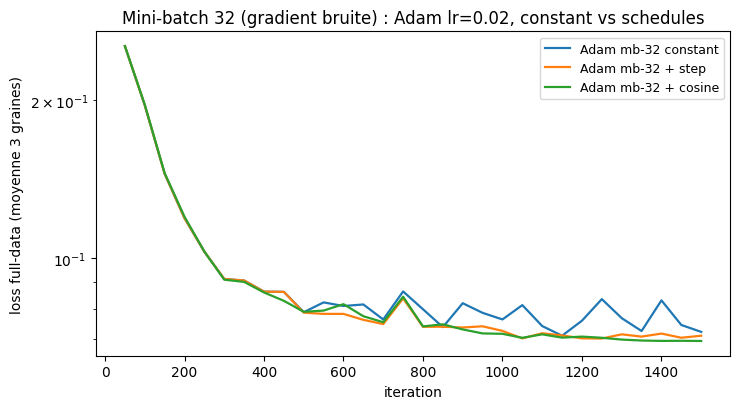

Adam mb-32 constant    loss finale mediane (3 graines) : 0.0715
Adam mb-32 + step      loss finale mediane (3 graines) : 0.0723
Adam mb-32 + cosine    loss finale mediane (3 graines) : 0.0683


In [9]:
# Regime (b) : gradient bruite (mini-batch 32), Adam lr=0.02, constant vs schedules
def train_adam_mb(seed, lr, schedule=None, batch=32):
    rng = np.random.RandomState(seed + 1000)
    p = mlp_init(seed)
    m = [np.zeros_like(q) for q in p]; v = [np.zeros_like(q) for q in p]
    hist = []
    for t in range(1, ITERS + 1):
        lr_t = schedule(t, lr) if schedule else lr
        idx = rng.randint(0, X_m.shape[0], batch)
        _, g = mlp_loss_grads(p, X_m[idx], Y_m[idx])
        for i in range(len(p)):
            m[i] = 0.9 * m[i] + 0.1 * g[i]
            v[i] = 0.999 * v[i] + 0.001 * g[i] ** 2
            p[i] = p[i] - lr_t * (m[i] / (1 - 0.9 ** t)) / (np.sqrt(v[i] / (1 - 0.999 ** t)) + 1e-8)
        if t % 50 == 0:
            hist.append((t, mlp_loss_grads(p, X_m, Y_m)[0]))
    return hist

mb_runs = {
    "Adam mb-32 constant": [train_adam_mb(s, 0.02) for s in SEEDS_MLP],
    "Adam mb-32 + step": [train_adam_mb(s, 0.02, sched_step) for s in SEEDS_MLP],
    "Adam mb-32 + cosine": [train_adam_mb(s, 0.02, sched_cosine) for s in SEEDS_MLP],
}
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, runs in mb_runs.items():
    ts = [t for t, _ in runs[0]]
    ax.plot(ts, np.mean([[l for _, l in r] for r in runs], axis=0), lw=1.6, label=name)
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("loss full-data (moyenne 3 graines)")
ax.set_title("Mini-batch 32 (gradient bruite) : Adam lr=0.02, constant vs schedules")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

for name, runs in mb_runs.items():
    finals = sorted(r[-1][1] for r in runs)
    print(f"{name:22s} loss finale mediane (3 graines) : {finals[1]:.4f}")

**Lecture (mini-batch).** Les trois méthodes utilisent, pour chaque graine, les mêmes tirages avec remise. Lisez les médianes et trajectoires ci-dessus : un éventuel écart dépend de ces données, du budget et des taux, et n’établit pas à lui seul un plancher de bruit.


## Exercice 2 : AdamW et L2

AdamW applique le decay aux **anciens** paramètres avant ou simultanément au pas Adam ; avec `weight_decay=.01`, vérifiez trois gradients contre `torch.optim.AdamW`. Comparez ensuite Adam avec pénalité L2 dont le gradient est effectivement couplé, et AdamW découplé, sur le même objectif de base. Avec graine 0, 400 pas, lr=.005 et weight_decay=.01, `comparer_adam_l2_adamw` retourne `{nom: (paramètres, historique_de_loss_de_base)}` ; les huit pertes sont mesurées tous les 50 pas. Les fixtures rejouent les deux moteurs PyTorch.


In [10]:
# Exercice 2 : AdamW et comparaison à Adam avec gradient L2 couplé.
def adamw_step(params, grads, state, lr=.05, weight_decay=.01, t=1):
    return NotImplemented  # TODO : decay sur les anciens paramètres, puis pas Adam

def comparer_adam_l2_adamw():
    return None  # TODO : 400 pas lr=.005, graine 0, weight_decay=.01, états et pertes aux multiples de 50

p=[np.array([1.,-2.])];state=make_adam_state(p)
if adamw_step(p,[np.array([2.,-3.])],state) is NotImplemented:
    print("Exercice 2 à compléter")
else:
    try:
        p=[np.array([1.,-2.])];state=make_adam_state(p);q=torch.tensor([1.,-2.],dtype=torch.float64,requires_grad=True)
        opt=torch.optim.AdamW([q],lr=.05,weight_decay=.01);ok=True
        for t,g in enumerate((np.array([2.,-3.]),np.array([-.5,1.25]),np.array([3.,.2])),1):
            adamw_step(p,[g],state,t=t);q.grad=torch.tensor(g,dtype=torch.float64);opt.step();opt.zero_grad();ok &= np.allclose(p[0],q.detach().numpy(),rtol=1e-12,atol=1e-12)
        comparison=comparer_adam_l2_adamw();ok &= comparison is not None
        if comparison is not None:
            ok &= set(comparison)=={"Adam L2","AdamW"}
            for name,(model,history) in comparison.items():
                q=[torch.tensor(v,dtype=torch.float64,requires_grad=True) for v in mlp_init(0)]
                opt=(torch.optim.Adam(q,lr=.005,weight_decay=.01) if name=="Adam L2" else torch.optim.AdamW(q,lr=.005,weight_decay=.01));expected=[]
                for t in range(1,401):
                    z=torch.relu(torch.tensor(X_m,dtype=torch.float64)@q[0]+q[1])@q[2]+q[3]
                    loss=torch.nn.functional.cross_entropy(z,torch.tensor(y_m,dtype=torch.long));loss.backward();opt.step();opt.zero_grad()
                    if t%50==0:expected.append(mlp_loss_grads([v.detach().numpy() for v in q],X_m,Y_m)[0])
                ok &= len(model)==4 and all(np.shape(a)==tuple(b.shape) and np.isfinite(a).all() for a,b in zip(model,q)) and len(history)==8 and np.isfinite(history).all() and np.allclose(history,expected,rtol=1e-8,atol=1e-8) and all(np.allclose(a,b.detach().numpy(),rtol=1e-8,atol=1e-8) for a,b in zip(model,q))
        print("Fixtures AdamW validées" if ok else "Réponse incorrecte")
    except (TypeError,ValueError,IndexError,AttributeError): print("Réponse incorrecte")


Exercice 2 à compléter


***

## 8. Le pont : retrouver ces optimisateurs dans les autres séries

Ce notebook a ouvert les cinq boîtes ; partout ailleurs du dépôt, elles sont refermées mais
vous savez maintenant ce qu'elles contiennent :

- **[RL](../../../RL/README.md) et PostTraining** : `torch.optim.Adam(model.parameters(), lr=...)`
  — les $(\beta_1, \beta_2, \varepsilon)$ par défaut de ce notebook, la correction de biais
  de la section 4 tournant à chaque step ;
- **ML-Training-Pipeline** : le lr schedule cosine de la section 7 est celui des entraînements
  réels (souvent avec warmup — exercice 3) ;
- **[3.4 (transformer)](README.md)** : le mini-GPT s'entraînera sous AdamW — l'exercice 2 vous
  l'aura déjà écrit.

La règle de lecture : quand une courbe d'entraînement fait quelque chose d'étrange dans les
100 premières itérations, examiner l’échelle du pas, les moments et le schedule, sans en déduire à eux seuls une causalité.

## Exercice 3 : warmup linéaire

Implémentez `lr * min(1,t/200)` puis comparez sur 400 pas Adam mini-batch 32 avec et sans warmup, pour trois graines et batches appariés. `comparer_warmup` retourne pour chaque graine deux bras `froid` et `warmup`, chacun avec paramètres et huit pertes full-data, une tous les 50 pas. Les fixtures vérifient les bornes du schedule et rejouent les deux bras avec l’optimiseur PyTorch réel.


In [11]:
# Exercice 3 : warmup et expériences appariées sur 400 pas mini-batch.
def sched_warmup(t, lr):
    return None  # TODO

def comparer_warmup():
    return None  # TODO : {graine: {"froid": (paramètres,histoire), "warmup": (...)}}

if sched_warmup(100,.02) is None:
    print("Exercice 3 à compléter")
else:
    try:
        ok=all(np.isclose(sched_warmup(t,lr),lr*min(1.,t/200)) for lr in (.02,.1) for t in (0,1,100,200,400))
        result=comparer_warmup();ok &= result is not None
        if result is not None:
            ok &= set(result)=={0,1,2}
            for seed,arms in result.items():
                ok &= set(arms)=={"froid","warmup"}
                for mode,(model,history) in arms.items():
                    # Oracle torch.optim.Adam ; tirages identiques entre les deux bras.
                    rng=np.random.RandomState(seed+1000);q=[torch.tensor(v,dtype=torch.float64,requires_grad=True) for v in mlp_init(seed)]
                    opt=torch.optim.Adam(q,lr=.02);expected=[]
                    for t in range(1,401):
                        opt.param_groups[0]["lr"]=.02*(min(1.,t/200) if mode=="warmup" else 1.);idx=rng.randint(0,X_m.shape[0],32)
                        z=torch.relu(torch.tensor(X_m[idx],dtype=torch.float64)@q[0]+q[1])@q[2]+q[3]
                        loss=torch.nn.functional.cross_entropy(z,torch.tensor(y_m[idx],dtype=torch.long));loss.backward();opt.step();opt.zero_grad()
                        if t%50==0:expected.append(mlp_loss_grads([v.detach().numpy() for v in q],X_m,Y_m)[0])
                    ok &= len(model)==4 and all(np.shape(a)==tuple(b.shape) and np.isfinite(a).all() for a,b in zip(model,q)) and len(history)==len(expected) and np.isfinite(history).all() and np.allclose(history,expected,rtol=1e-8,atol=1e-8) and all(np.allclose(a,b.detach().numpy(),rtol=1e-8,atol=1e-8) for a,b in zip(model,q))
        print("Fixtures warmup validées" if ok else "Réponse incorrecte")
    except (TypeError,ValueError,IndexError,AttributeError): print("Réponse incorrecte")


Exercice 3 à compléter


## Contre-sens usuels sur les optimisateurs

- Les moments Adam deviennent non nuls dès le premier gradient : la correction de biais rééchelonne leurs estimateurs et peut réduire ou augmenter le pas.
- Nesterov dépend de la convention de coordonnées ; le contrôle ci-dessus porte sur la convention PyTorch.
- AdamW découple le decay, alors que L2 couplé modifie le gradient avant normalisation.
- Une comparaison sur plusieurs pas contrôle les paramètres pour les fixtures, sans démontrer une supériorité générale.
- Un schedule ne garantit pas un gain : données, taux, bruit et budget comptent.


***

## Conclusion et transition

Le réseau de 3.1 et les optimiseurs étudiés ici constituent un entraînement complet. Le choix du taux, la correction de biais et le schedule doivent être examinés selon les données et le budget. La [régularisation en 3.3](README.md) prolongera cet entraînement pour limiter le surapprentissage.

## À retenir

- **GD** suit le gradient courant avec un taux global ; **momentum** accumule un état qui influence les pas suivants.
- **Adagrad** accumule les carrés des gradients ; **RMSProp** utilise une moyenne glissante ; **Adam** combine deux moments et corrige leur biais d’initialisation.
- Les cinq règles ont été comparées à leurs API réelles sur plusieurs gradients, puis mesurées sur Beale et sur un MLP. Les différences dépendent des taux, données et budgets.
- Les schedules constant, step et cosine sont comparés en full-batch puis sur des mini-batches appariés. Les exercices prolongent Nesterov, AdamW et warmup.

Poursuivez avec [3.3 — Régularisation](README.md).

## References

1. Polyak, B. T. (1964). *Some methods of speeding up the convergence of iteration methods*. USSR Computational Mathematics and Mathematical Physics 4(5):1-17.
2. Duchi, J., Hazan, E., & Singer, Y. (2011). *Adaptive subgradient methods for online learning and stochastic optimization*. JMLR 12:2121-2159.
3. Tieleman, T., & Hinton, G. (2012). *Lecture 6.5 — RMSProp*. Coursera: Neural Networks for Machine Learning.
4. Kingma, D. P., & Ba, J. (2014). *Adam: A method for stochastic optimization*. arXiv:1412.6980.
5. Loshchilov, I., & Hutter, F. (2019). *Decoupled weight decay regularization (AdamW)*. ICLR.

## Vérifiez votre compréhension

1. Que conserve momentum entre deux pas ?
2. Que corrige la correction de biais d’Adam ?
3. Quelle différence entre L2 couplé et AdamW ?
4. Pourquoi un schedule n’est-il pas toujours gagnant ?

<details><summary>Réponses</summary>

1. Un accumulateur de gradients. 2. L’initialisation à zéro des estimateurs de moments ; le premier pas non corrigé n’est pas forcément petit. 3. L2 modifie le gradient, AdamW applique le decay aux anciens paramètres. 4. Son effet dépend du taux, du bruit et du budget.

</details>


## Pour aller plus loin

- [PyTorch : optimiseurs](https://docs.pytorch.org/docs/stable/optim.html).
- [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html).
- [Références du carnet](#references).
